## This is final version of the code for ELR as base line for QRF paper (Bohar) 
## currently I am running the script with my_env enviornment 

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
import pandas as pd
import elr_c as elr
import utils_b as utils

In [2]:
# lead week 1 [0, 7],week 2 [7, 14] week 34 [14, 28]
week = "Week2"
lead = (7, 14) 

## Open Training and Test data set 

In [3]:
# GEFS model data 
train_model = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/GEFS_pra_1989-2010.nc")['prcp']
t = train_model['S'] + pd.Timedelta(days=(lead[0] + lead[1]) / 2)
train_model = train_model.assign_coords(T=('S', t.values)).swap_dims(S='T')
test_model = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/GEFS_pra_2022-2024.nc")['prcp']
t1 = test_model['S'] + pd.Timedelta(days=(lead[0] + lead[1]) / 2)
test_model = test_model.assign_coords(T=('S', t1.values)).swap_dims(S='T')

# IMD observstion data 
train_obs = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/IMD_pra_1989-2010.nc")['prcp']
test_obs = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/IMD_pra_2022-2024.nc")['prcp']


In [4]:
test_model1=test_model[0:50,:,:,:]*86400
mean_over_M = test_model1.mean(dim='M', skipna=True)
#mean_over_M 
test_obs1 =test_obs[0:50,:,:]
test_obs1

<xarray.DataArray 'prcp' (T: 50, Y: 32, X: 31)> Size: 198kB
[49600 values with dtype=float32]
Coordinates:
  * Y        (Y) float32 128B 7.0 8.0 9.0 10.0 11.0 ... 34.0 35.0 36.0 37.0 38.0
  * X        (X) float32 124B 68.0 69.0 70.0 71.0 72.0 ... 95.0 96.0 97.0 98.0
  * T        (T) datetime64[ns] 400B 2022-06-14T12:00:00 ... 2024-09-10T12:00:00
Attributes:
    pointwidth:          0
    long_name:           GRIDDED RAINFALL
    standard_name:       rainfall_rate
    ncolor:              254
    maxncolor:           254
    colorscalename:      precip_colors
    colormap:            [null 16777215 16777215 16777215 [16777215 3] 141557...
    file_missing_value:  -999.0
    units:               mm/day
    history:             [(Boxes with less than 0.0% dropped) (Averaged in T ...

## Training ELR model

In [5]:
def make_ohe(array):
    """
    Converts a (T, Y, X) array into a one-hot encoded array (T, 3, Y, X)
    based on per-grid quantile thresholds (1/3, 2/3), handling NaNs.

    Parameters:
        array: np.ndarray of shape (T, Y, X), possibly with NaNs.

    Returns:
        ohe: np.ndarray of shape (T, 3, Y, X) with NaNs preserved.
        p_33, p_67: np.ndarray of shape (Y, X) — 33rd and 67th percentiles.
    """
    p_33 = np.nanquantile(array, q=1/3, axis=0)
    p_67 = np.nanquantile(array, q=2/3, axis=0)
    
    T, Y, X = array.shape
    ohe = np.zeros((T, 3, Y, X), dtype=np.float32)

    # Create class masks
    mask_low = array <= p_33
    mask_mid = (array > p_33) & (array <= p_67)
    mask_high = array > p_67
    mask_nan = np.isnan(array)

    ohe[:, 0][mask_low] = 1
    ohe[:, 1][mask_mid] = 1
    ohe[:, 2][mask_high] = 1

    # Expand mask_nan to match ohe shape: (T, 3, Y, X)
    nan_mask_expanded = np.broadcast_to(mask_nan[:, None, :, :], ohe.shape)
    ohe[nan_mask_expanded] = np.nan

    return ohe, p_33, p_67


In [6]:
def make_ohe_as_elr(array):
    """
    Converts a (T, Y, X) array into a class-labeled array (-1, 0, 1),
    based on per-grid quantile thresholds (1/3, 2/3), handling NaNs.

    Parameters:
        array: np.ndarray of shape (T, Y, X), possibly with NaNs.

    Returns:
        np.ndarray of shape (T, Y, X) with class labels and NaNs.
        -1 = below normal, 0 = near normal, 1 = above normal
    """
    p_33 = np.nanquantile(array, q=1/3, axis=0)
    p_67 = np.nanquantile(array, q=2/3, axis=0)

    class_array = np.full_like(array, np.nan, dtype=np.float32)

    class_array[array <= p_33] = -1
    class_array[(array > p_33) & (array <= p_67)] = 0
    class_array[array > p_67] = 1

    return class_array


In [7]:
labeler = utils.make_tercile_labeler(train_obs)
train_cat = labeler(train_obs)
test_cat = labeler(test_obs1)
test_cat_50 =test_cat[0:50,:,:]

/Users/bohar/anaconda3/envs/my_env/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


In [8]:
"""
# Identify points that are zero or NaN across the entire T dimension
all_zero_grids = (classes_xr == -1).all(dim='T')

# Now filter only grid points where it's ALL zero or NaN
zero_only_grids = all_zero_grids.where(all_zero_grids, drop=True)

# Print Y and X coordinates of those grids
print("Grid points with all zero or NaN over time:")
for y in zero_only_grids['Y'].values:
    for x in zero_only_grids['X'].values:
        if zero_only_grids.sel(Y=y, X=x).values:
            print(f"Y={y}, X={x}")
"""

'\n# Identify points that are zero or NaN across the entire T dimension\nall_zero_grids = (classes_xr == -1).all(dim=\'T\')\n\n# Now filter only grid points where it\'s ALL zero or NaN\nzero_only_grids = all_zero_grids.where(all_zero_grids, drop=True)\n\n# Print Y and X coordinates of those grids\nprint("Grid points with all zero or NaN over time:")\nfor y in zero_only_grids[\'Y\'].values:\n    for x in zero_only_grids[\'X\'].values:\n        if zero_only_grids.sel(Y=y, X=x).values:\n            print(f"Y={y}, X={x}")\n'

In [9]:
tt1= train_obs.values
tt2 = test_obs1.values
classes = make_ohe_as_elr(tt1)
classes_tst = make_ohe_as_elr(tt2)
classes.shape
Y = train_cat.coords["Y"]
X = train_cat.coords["X"]
T = train_cat.coords["T"]

# Create the DataArray
classes_xr = xr.DataArray(
    data=classes,
    dims=["T", "Y", "X"],
    coords={"T": T, "Y": Y, "X": X},
    name="prcp"
)

T = mean_over_M.coords["T"]
# Create the DataArray
classes_test = xr.DataArray(
    data=classes_tst,
    dims=["T", "Y", "X"],
    coords={"T": T, "Y": Y, "X": X},
    name="prcp"
)

# Optional: add a quantile coordinate if you want to associate this with 0.333
#classes_xr = classes_xr.expand_dims({"quantile": [0.3333]})  # If this applies contextually

# here we are labeling manually x=93 and Y =22 point is equal to nan
classes_xr.loc[:, 22, 93] = np.nan
classes_test.loc[:, 22, 93] = np.nan
#classes_test

/Users/bohar/anaconda3/envs/my_env/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


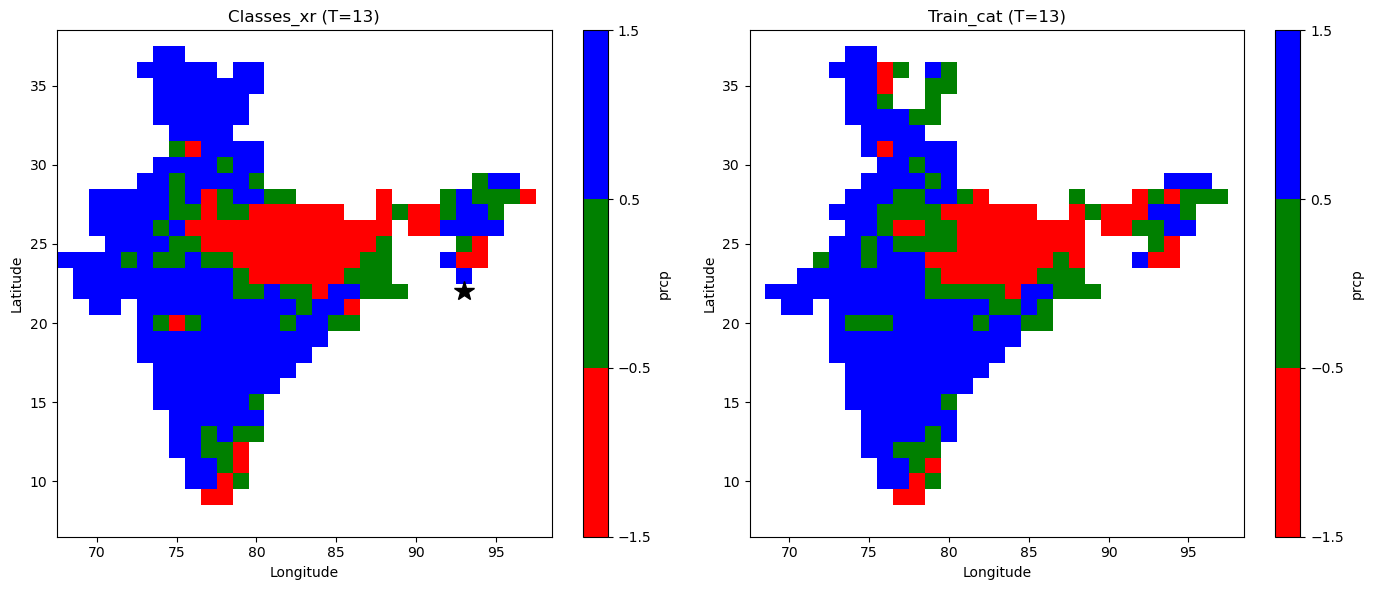

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Coordinates to highlight
highlight_x = 93
highlight_y = 22

# Find the corresponding index values
x_coord = float(classes_xr.X.sel(X=highlight_x).values)
y_coord = float(classes_xr.Y.sel(Y=highlight_y).values)
# Select timestep
mm = classes_test.isel(T=24)
nn = test_cat_50.isel(T=24)


# Define custom colormap: -1 (red), 0 (green), 1 (blue)
cmap = mcolors.ListedColormap(['red', 'green', 'blue'])
bounds = [-1.5, -0.5, 0.5, 1.5]
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# Create 1x2 panel plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot mm
mm.plot(ax=axes[0], cmap=cmap, norm=norm)
axes[0].set_title("Classes_xr (T=13)")
axes[0].plot(x_coord, y_coord, marker='*', color='black', markersize=15)
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

# Plot nn
nn.plot(ax=axes[1], cmap=cmap, norm=norm)
axes[1].set_title("Train_cat (T=13)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()


In [11]:
predict_elr = elr.train(train_model, classes_xr )

In [12]:
vfcst_elr = predict_elr(test_model1)

In [13]:

from scipy.ndimage import gaussian_filter

# vfcst_elr xarray.DataArray with the dimensions: ('T', 'category', 'Y', 'X')

# Apply Gaussian smoothing on the 'category' dimension
# The sigma parameter controls the width of the smoothing kernel (you can adjust it as needed)
def apply_gaussian_smoothing(arr, sigma=1):
    # We apply the filter along the 'category' axis (axis 1 in this case)
    smoothed = gaussian_filter(arr, sigma=(0, sigma, 0, 0), mode='nearest')
    return smoothed

In [14]:
# Apply the smoothing function on the DataArray 'prcp'
#smoothed_prcp = vfcst_elr.copy()
#smoothed_prcp.values = apply_gaussian_smoothing(vfcst_elr.values, sigma=1)

# Rescale the smoothed probabilities so that their sum across the 'category' dimension is 1
# Normalize along the 'category' dimension (axis 1)
#rescaled_prcp = smoothed_prcp / smoothed_prcp.sum(dim='category', keepdims=True)

# Verify the sum of the probabilities across the 'category' dimension is 1
#print(rescaled_prcp.sum(dim='category'))

In [15]:
import geopandas as gpd
# Load the shapefile
shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/indian_borders.shp"  # Update with your actual file path
State_shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/sd_boundary.shp"  # Update with your actual file path
gdf = gpd.read_file(shapefile_path)
gdf_st = gpd.read_file(State_shapefile_path)

In [16]:
#test_cat_50

In [17]:
tt= vfcst_elr
low =np.nanmin(tt.values)
high= np.nanmax(tt.values)
print(f'Range:,{low},-,{high}' )

Range:,4.862975482287173e-05,-,0.8027006244930852


In [18]:
rps_elr = utils.rps(test_cat_50, vfcst_elr) 
rps_elr_new = utils.rps(classes_test, vfcst_elr)
vfcst_clim = utils.climo_predict(test_model1)

rpss_new = utils.rpss(vfcst_clim, vfcst_elr, classes_test)
rpss = utils.rpss(vfcst_clim, vfcst_elr, test_cat_50)
rpss_elr=rpss_new-rpss

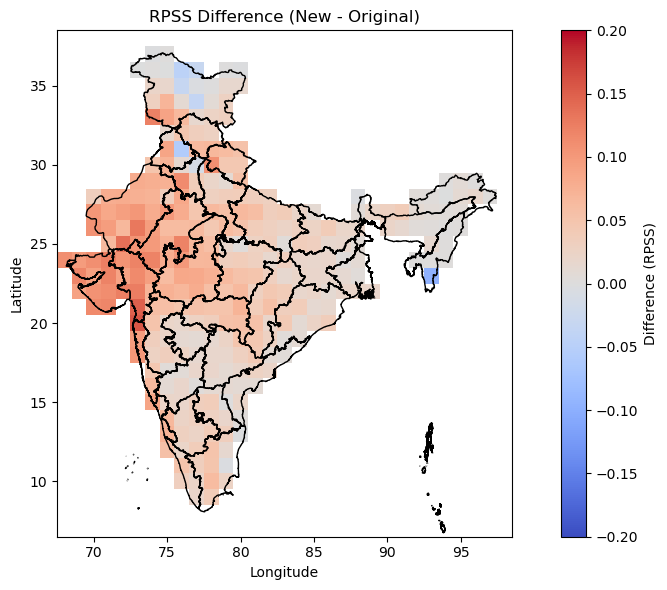

In [19]:
# Plot the xarray data
fig, ax = plt.subplots(figsize=(10, 6))

# Use pcolormesh instead of pcolor for better handling of grid edges (optional)
cs = ax.pcolormesh(rpss.X, rpss.Y, rpss_new, cmap="coolwarm", vmin=-0.2, vmax=0.20)

# Add colorbar
plt.colorbar(cs, ax=ax, label="Difference (RPSS)")

# Overlay the shapefile
gdf_st.plot(ax=ax, color="none", edgecolor="black", linewidth=1)

ax.set_title("RPSS Difference (New - Original)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()


In [20]:
# Check if all values in 'prcp' are NaN
all_nan = vfcst_elr.isnull().all().item()

# Print the result
print("All values are NaN:", all_nan)

All values are NaN: False


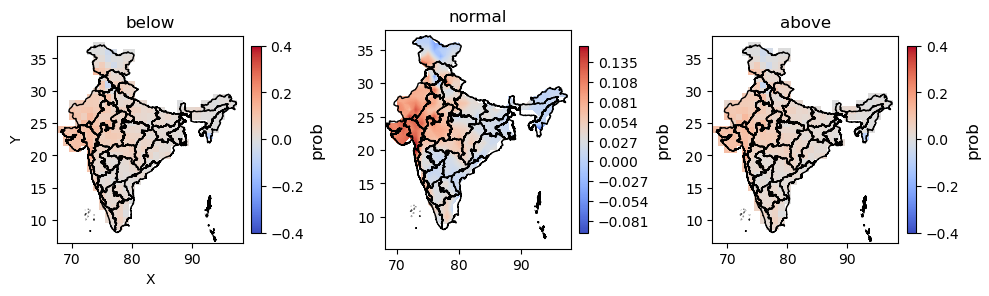

In [21]:
# Create a 2x3 subplot
fig, ax = plt.subplots(1, 3, figsize=(10, 20))

# Plot the data on the first subplot (e.g., for a specific Y, X slice)
cs = rpss_new.plot(ax=ax[0], cmap="coolwarm", vmin=-0.40, vmax =0.40, add_colorbar=False)
# Overlay the shapefile
gdf_st.plot(ax=ax[0], color="none", edgecolor="black", linewidth=1)
ax[0].set_title('below')
#axes[0].colorbar(label='Precipitation')
# Add a colorbar manually with an appropriate label
cbar = plt.colorbar(cs, ax=ax[0], fraction=0.046, pad=0.04)
cbar.set_label("prob", fontsize=12)

#subplot 2
cs = ax[1].contourf(rpss.X, rpss.Y, rpss_new, levels=200, cmap="coolwarm")
# Overlay the shapefile
gdf_st.plot(ax=ax[1], color="none", edgecolor="black", linewidth=1)
ax[1].set_title('normal')
# Add a colorbar manually with an appropriate label
cbar = plt.colorbar(cs, ax=ax[1], fraction=0.046, pad=0.04)
cbar.set_label("prob", fontsize=12)

#subplot 3
cs = ax[2].pcolor(rpss.X, rpss.Y, rpss_new, cmap="coolwarm", vmin=-0.40, vmax=0.40)
# Overlay the shapefile
gdf_st.plot(ax=ax[2], color="none", edgecolor="black", linewidth=1)
ax[2].set_title('above')
# Add a colorbar manually with an appropriate label
cbar = plt.colorbar(cs, ax=ax[2], fraction=0.046, pad=0.04)
cbar.set_label("prob", fontsize=12)

# Adjust layout for better spacing
plt.tight_layout()

In [22]:
from scipy.ndimage import gaussian_filter

In [23]:
#data=rpss
data=rpss_new
# Create a mask to preserve NaN locations
nan_mask = np.isnan(data)

# Temporarily fill NaNs with the mean of finite values to avoid distortion
filled_data = data.fillna(data.mean())

# Apply Gaussian filter (sigma=1 for moderate smoothing, adjust as needed)
smoothed_data = gaussian_filter(filled_data, sigma=1)

# Restore NaN values in their original locations
smoothed_data = xr.DataArray(smoothed_data, coords=data.coords, dims=data.dims)
smoothed_data = smoothed_data.where(~nan_mask)


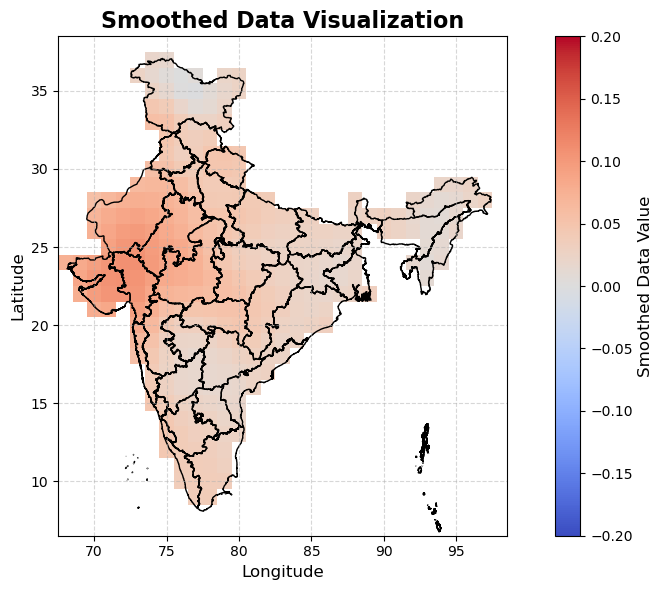

In [24]:
import matplotlib.pyplot as plt

# Create a figure and axis with specific size
fig, ax = plt.subplots(figsize=(10, 6))

# Plot the smoothed data with no automatic colorbar
smoothed_plot = smoothed_data.plot(ax=ax, cmap="coolwarm", vmin=-0.2, vmax=0.2, add_colorbar=False)

# Overlay the shapefile with proper styling, ensuring it's on top of the data
gdf_st.plot(ax=ax, color="none", edgecolor="black", linewidth=1)

# Add a colorbar manually with an appropriate label
cbar = plt.colorbar(smoothed_plot, ax=ax)
cbar.set_label("Smoothed Data Value", fontsize=12)

# Set title and axis labels
ax.set_title("Smoothed Data Visualization", fontsize=16, weight='bold')
ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)

# Improve axis ticks and gridlines for readability
ax.tick_params(axis='both', labelsize=10)
ax.grid(True, linestyle="--", alpha=0.5)

# Tight layout for better fitting of elements
plt.tight_layout()

# Show the plot
plt.show()


In [ ]:
# save probability 
rpss_new.to_netcdf(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_rpss_{week}_2022_2024.nc")
rps_elr_new.to_netcdf(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_rps_{week}_2022_2024.nc")

In [ ]:
def convert_to_onehot(test_cat: xr.DataArray) -> xr.DataArray:
    """
    Converts a categorical DataArray with values -1, 0, 1, or NaN to one-hot encoded format.
    
    Parameters:
    -----------
    test_cat : xr.DataArray
        Input categorical data with dims ('T', 'Y', 'X') and values -1, 0, 1, or NaN.

    Returns:
    --------
    onehot_cat : xr.DataArray
        One-hot encoded DataArray with dims ('T', 'category', 'Y', 'X'), shape (T, 3, Y, X)
    """
    # getting shape
    p ,q, r =test_cat.shape
    # Initialize an empty array for one-hot values
    onehot_array = np.full((p, 3, q, r), np.nan)

    # Create masks for each category
    mask_below = test_cat == -1
    mask_normal = test_cat == 0
    mask_above = test_cat == 1
    mask_nan = test_cat.isnull()

    # Assign one-hot values
    onehot_array[:, 0, :, :] = mask_below.values.astype(float)  # [1 0 0]
    onehot_array[:, 1, :, :] = mask_normal.values.astype(float) # [0 1 0]
    onehot_array[:, 2, :, :] = mask_above.values.astype(float)  # [0 0 1]

    # Set NaNs where original data was NaN
    onehot_array[:, :, :, :] = np.where(np.expand_dims(mask_nan.values, axis=1), np.nan, onehot_array)

    # Create new coordinates and DataArray
    onehot_cat = xr.DataArray(
        onehot_array,
        dims=('T', 'category', 'Y', 'X'),
        coords={
            'T': test_cat.coords['T'].isel(T=slice(0, 50)),
            'category': ['below', 'normal', 'above'],
            'Y': test_cat.coords['Y'],
            'X': test_cat.coords['X']
        },
        name='prcp'
    )

    return onehot_cat


In [ ]:
#saving test categoty
ohe_testobs_elr = convert_to_onehot(test_cat_50) 
ohe_testobs_elr_new = convert_to_onehot(classes_test)
ohe_testobs_elr_new.to_netcdf(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_category_{week}_2022_2024.nc")



In [ ]:
#Saving forecast probability
vfcst_elr.to_netcdf(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_{week}_2022_2024.nc")

In [ ]:
mm =ohe_testobs_elr_new[13,2,:,:]
mm.plot()